# 🚗 Car Price Prediction — Audi Dataset

**Goal:** Predict the resale `price` of used Audi cars from attributes such as model, year,
transmission, mileage, fuel type, road tax, mpg and engine size.

**Dataset:** `audi.csv` (10,668 rows × 9 columns)

**Workflow**
1. Imports & setup
2. Load data
3. Automated EDA (ydata-profiling)
4. Manual EDA (structure, nulls, duplicates, stats, visualizations)
5. Feature engineering (encoding, scaling)
6. Train/test split
7. Model building — Linear Regression, Random Forest, Extra Trees, CatBoost
8. Hyperparameter tuning (RandomizedSearchCV)
9. Model comparison & selection
10. Persist the best model (pickle)
11. Reload the model and score on fresh data


## 1. Import Libraries

In [1]:
import os
import warnings
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
%matplotlib inline

# Modelling
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Gradient boosting model
# Install catboost if not already installed
try:
    from catboost import CatBoostRegressor
except ImportError:
    !pip install catboost
    from catboost import CatBoostRegressor

print('Libraries imported successfully')

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/100.2 MB 1.5 MB/s eta 0:01:06
   ---------------------------------------- 0.5/100.2 MB 1.5 MB/s eta 0:01:06
   ---------------------------------------- 0.8/100.2 MB 957.1 kB/s eta 0:01:44
   ---------------------------------------- 1.0/100.2 MB 1.1 MB/s eta 0:01:27
    --------------------------------------- 1.3/100.2 MB 1.2 MB/s eta 0:01:22
    --------------------------------------- 1.6/100.2 MB 1.1 MB/s eta 0:01:33
    --------------------------------------- 1.8/100.2 MB 1.1 MB/s eta 0:01:30
    --------------------------------------- 1.8/100.2 MB 1.1 MB/s eta 0:01:30
    --------------------------------------- 2.1/100.2 MB 986.6 kB/s eta 0:01:40
    --------------------------------------- 2.4/100.2 MB 990.8 kB/s eta 0:01:39
 

> **Note on installs** — if any of the packages below are missing in your environment, install them first:
> ```bash
> pip install pandas numpy matplotlib seaborn scikit-learn catboost ydata-profiling
> ```

## 2. Load the Data

In [2]:
print('Current working directory:', os.getcwd())



Current working directory: C:\Users\TANU\00-ACME--T\Car Price Prediction


In [4]:
df = pd.read_csv("audi.csv")
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0


## 3. Automated EDA — Pandas/ydata Profiling Report

Generates a full one-shot exploratory report (distributions, correlations, missing values,
alerts). This can take a little while to render — set `minimal=True` for a faster summary.
The report is also saved to `audi_profile_report.html` so it can be viewed outside the notebook.

In [5]:
try:
    from ydata_profiling import ProfileReport

    profile = ProfileReport(df, title="Audi Car Price - Profiling Report", minimal=True, explorative=False)
    profile.to_file("audi_profile_report.html")
    profile.to_notebook_iframe()
except ImportError:
    print("ydata-profiling not installed — skipping automated report.\n"
          "Install with: pip install ydata-profiling")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 11.16it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## 4. Manual EDA

In [6]:
# Number of records
print("Number of records:", len(df))

# Shape
print("Shape (rows, columns):", df.shape)

Number of records: 10668
Shape (rows, columns): (10668, 9)


In [7]:
# Data types
df.dtypes

model            object
year              int64
price             int64
transmission     object
mileage           int64
fuelType         object
tax               int64
mpg             float64
engineSize      float64
dtype: object

In [8]:
# Null values
df.isna().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [9]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10668 entries, 0 to 10667
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         10668 non-null  object 
 1   year          10668 non-null  int64  
 2   price         10668 non-null  int64  
 3   transmission  10668 non-null  object 
 4   mileage       10668 non-null  int64  
 5   fuelType      10668 non-null  object 
 6   tax           10668 non-null  int64  
 7   mpg           10668 non-null  float64
 8   engineSize    10668 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 750.2+ KB


In [10]:
# Duplicate records
dupes = df[df.duplicated()]
print(f"Number of duplicate rows: {len(dupes)}")
dupes.head()

Number of duplicate rows: 103


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
273,Q3,2019,34485,Automatic,10,Diesel,145,47.1,2.0
764,Q2,2019,22495,Manual,1000,Diesel,145,49.6,1.6
784,Q3,2015,13995,Manual,35446,Diesel,145,54.3,2.0
967,Q5,2019,31998,Semi-Auto,100,Petrol,145,33.2,2.0
990,Q2,2019,22495,Manual,1000,Diesel,145,49.6,1.6


In [11]:
# Descriptive statistics
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
model,10668,26,A3,1929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,10668.0,NaN,NaN,NaN,2017.100675,2.167494,1997.0,2016.0,2017.0,2019.0,2020.0
price,10668.0,NaN,NaN,NaN,22896.685039,11714.841888,1490.0,15130.75,20200.0,27990.0,145000.0
transmission,10668,3,Manual,4369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,10668.0,NaN,NaN,NaN,24827.244001,23505.257205,1.0,5968.75,19000.0,36464.5,323000.0
fuelType,10668,3,Diesel,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax,10668.0,NaN,NaN,NaN,126.011436,67.170294,0.0,125.0,145.0,145.0,580.0
mpg,10668.0,NaN,NaN,NaN,50.770022,12.949782,18.9,40.9,49.6,58.9,188.3
engineSize,10668.0,NaN,NaN,NaN,1.930709,0.602957,0.0,1.5,2.0,2.0,6.3


### 4.1 Target variable — `price` distribution

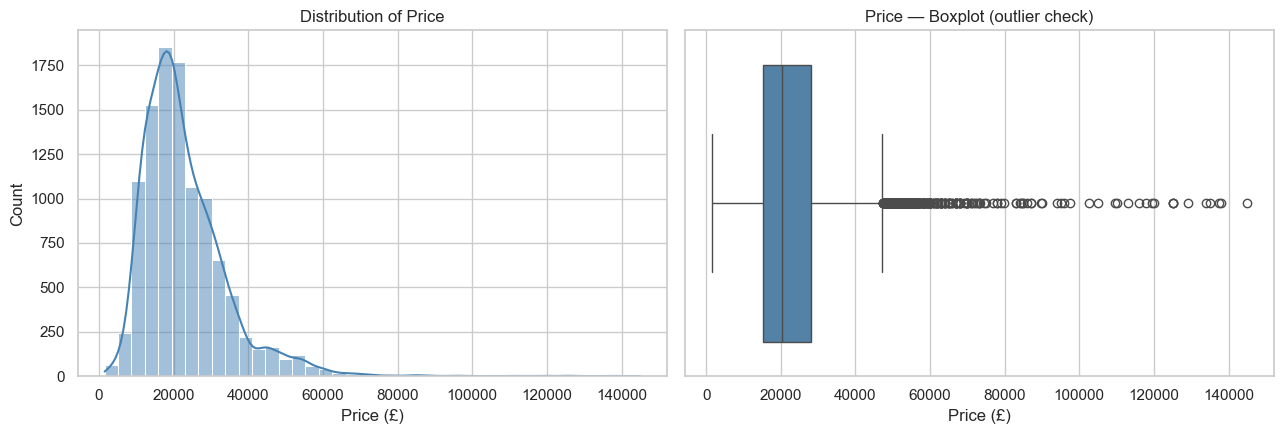

count     10668.000000
mean      22896.685039
std       11714.841888
min        1490.000000
25%       15130.750000
50%       20200.000000
75%       27990.000000
max      145000.000000
Name: price, dtype: float64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df['price'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Price')
axes[0].set_xlabel('Price (£)')

sns.boxplot(x=df['price'], ax=axes[1], color='steelblue')
axes[1].set_title('Price — Boxplot (outlier check)')
axes[1].set_xlabel('Price (£)')

plt.tight_layout()
plt.show()

print(df['price'].describe())

### 4.2 Categorical features

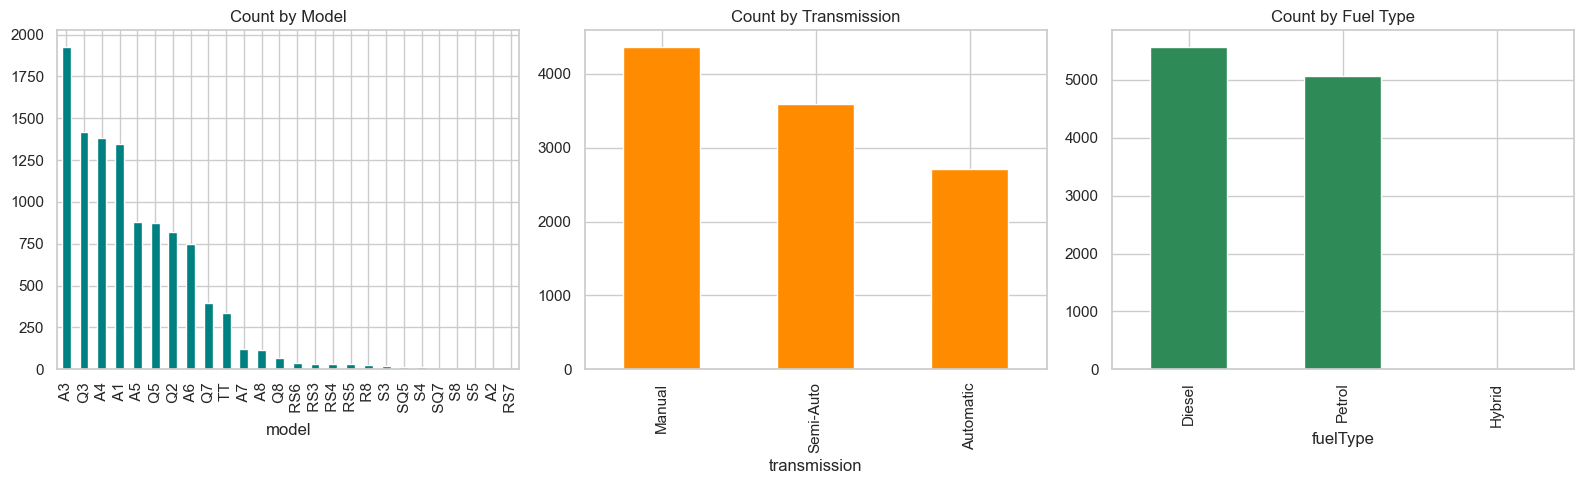

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df['model'].value_counts().plot(kind='bar', ax=axes[0], color='teal')
axes[0].set_title('Count by Model')
axes[0].tick_params(axis='x', labelrotation=90)

df['transmission'].value_counts().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Count by Transmission')

df['fuelType'].value_counts().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Count by Fuel Type')

plt.tight_layout()
plt.show()

### 4.3 Price vs key numeric/categorical features

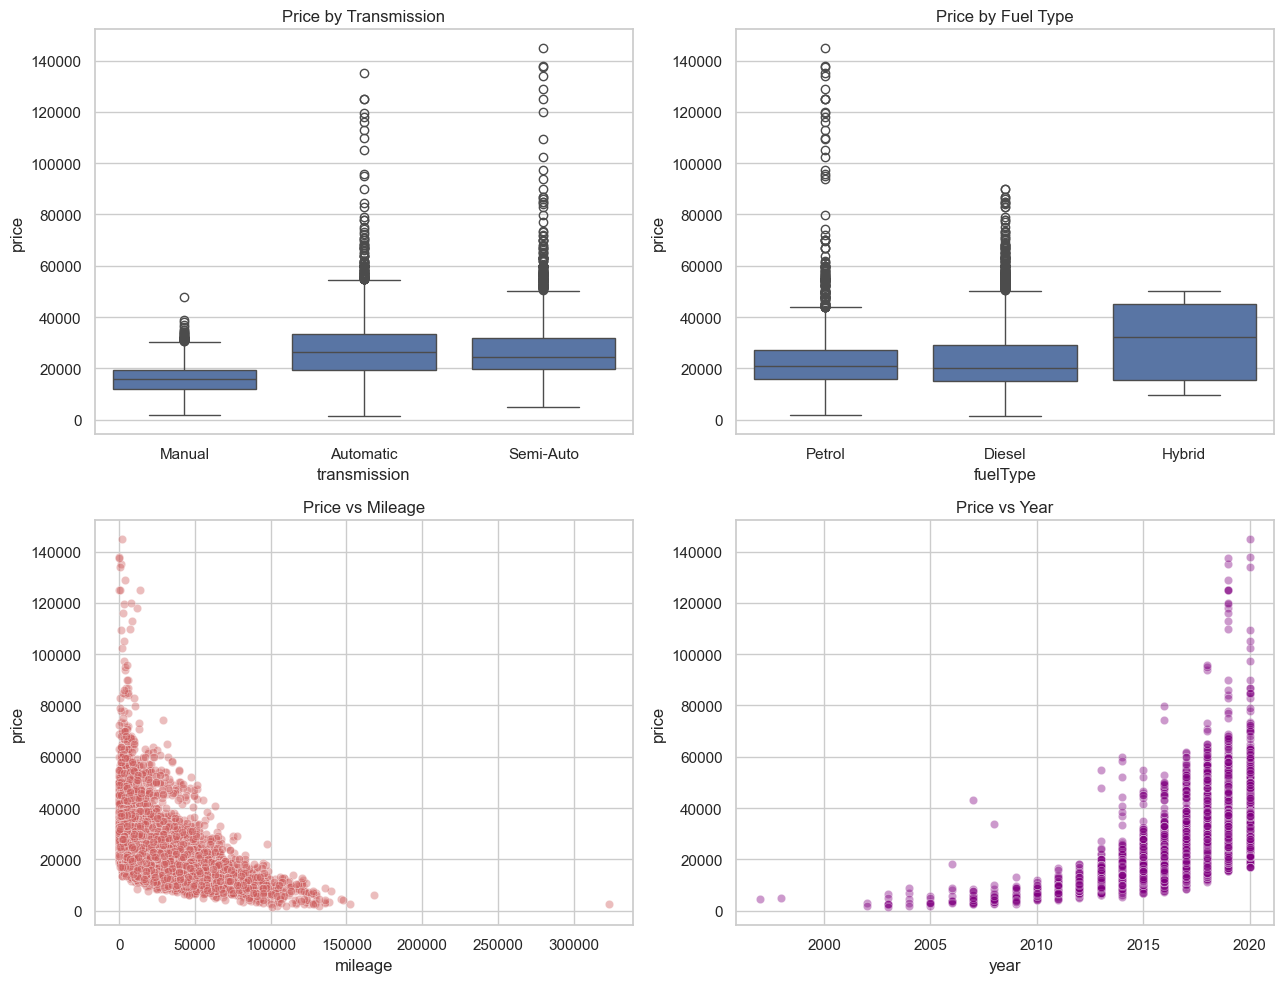

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.boxplot(data=df, x='transmission', y='price', ax=axes[0, 0])
axes[0, 0].set_title('Price by Transmission')

sns.boxplot(data=df, x='fuelType', y='price', ax=axes[0, 1])
axes[0, 1].set_title('Price by Fuel Type')

sns.scatterplot(data=df, x='mileage', y='price', alpha=0.4, ax=axes[1, 0], color='indianred')
axes[1, 0].set_title('Price vs Mileage')

sns.scatterplot(data=df, x='year', y='price', alpha=0.4, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Price vs Year')

plt.tight_layout()
plt.show()

### 4.4 Correlation heatmap (numeric features)

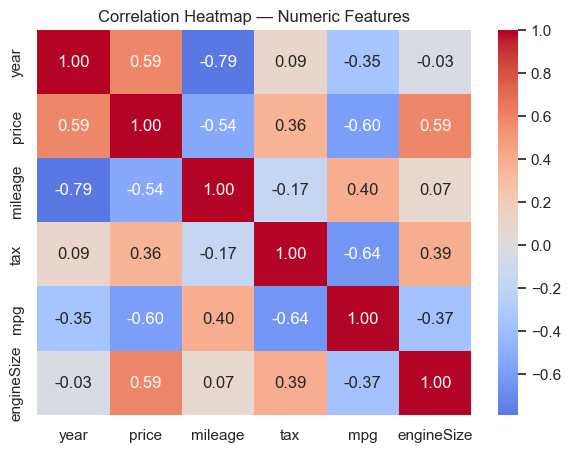

In [15]:
numeric_cols = df.select_dtypes(include=[np.number])
plt.figure(figsize=(7, 5))
sns.heatmap(numeric_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Numeric Features')
plt.show()

## 5. Feature Engineering

`price` (index 2) is the dependent variable. All other columns are used as features:
`model, year, transmission, mileage, fuelType, tax, mpg, engineSize`.

In [16]:
# Create X (features) and Y (target)
X = df.iloc[:, [0, 1, 3, 4, 5, 6, 7, 8]].values   # model, year, transmission, mileage, fuelType, tax, mpg, engineSize
Y = df.iloc[:, [2]].values                         # price

print("X shape:", X.shape)
print("Y shape:", Y.shape)
pd.DataFrame(X, columns=['model', 'year', 'transmission', 'mileage', 'fuelType', 'tax', 'mpg', 'engineSize']).head()

X shape: (10668, 8)
Y shape: (10668, 1)


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,Manual,1998,Petrol,145,49.6,1.0


### 5.1 Label Encoding — `model` and `fuelType`

In [17]:
le_model = LabelEncoder()
X[:, 0] = le_model.fit_transform(X[:, 0])

le_fuel = LabelEncoder()
X[:, -4] = le_fuel.fit_transform(X[:, -4])  # fuelType is 4th column from the end

pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7
0,0,2017,Manual,15735,2,150,55.4,1.4
1,5,2016,Automatic,36203,0,20,64.2,2.0
2,0,2016,Manual,29946,2,30,55.4,1.4
3,3,2017,Automatic,25952,0,145,67.3,2.0
4,2,2019,Manual,1998,2,145,49.6,1.0


### 5.2 One-Hot Encoding — `transmission`

In [18]:
ct = ColumnTransformer(
    transformers=[('encoder', OneHotEncoder(), [2])],
    remainder='passthrough'
)
X = ct.fit_transform(X)

print("X shape after one-hot encoding:", X.shape)
pd.DataFrame(X).head()

X shape after one-hot encoding: (10668, 10)


,0,1,2,3,4,5,6,7,8,9
0,0.0,1.0,0.0,0,2017,15735,2,150,55.4,1.4
1,1.0,0.0,0.0,5,2016,36203,0,20,64.2,2.0
2,0.0,1.0,0.0,0,2016,29946,2,30,55.4,1.4
3,1.0,0.0,0.0,3,2017,25952,0,145,67.3,2.0
4,0.0,1.0,0.0,2,2019,1998,2,145,49.6,1.0


### 5.3 Feature Scaling — Standardization

In [19]:
sc = StandardScaler()
X = sc.fit_transform(X)

pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7,8,9
0,-0.583268,1.200728,-0.712333,-1.123544,-0.046450,-0.386836,1.050783,0.357147,0.357550,-0.880218
1,1.714479,-0.832828,-0.712333,-0.160831,-0.507834,0.483989,-0.954181,-1.578323,1.037130,0.114925
2,-0.583268,1.200728,-0.712333,-1.123544,-0.507834,0.217781,1.050783,-1.429440,0.357550,-0.880218
3,1.714479,-0.832828,-0.712333,-0.545916,-0.046450,0.047853,-0.954181,0.282706,1.276528,0.114925
4,-0.583268,1.200728,-0.712333,-0.738459,0.876318,-0.971285,1.050783,0.282706,-0.090355,-1.543647


## 6. Train / Test Split

In [20]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

print("Full data:  ", X.shape, Y.shape)
print("Train data: ", X_train.shape, Y_train.shape)
print("Test data:  ", X_test.shape, Y_test.shape)

Full data:   (10668, 10) (10668, 1)
Train data:  (8534, 10) (8534, 1)
Test data:   (2134, 10) (2134, 1)


## 7. Model Building

We'll train several regressors and compare them on held-out test data using **R² score** and
**Mean Absolute Error (MAE)**. A results dictionary collects the metrics for a final comparison.

In [21]:
results = {}

def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {'R2 Score': r2, 'MAE': mae}
    print(f"{name}")
    print(f"  R2 Score : {r2:.4f}")
    print(f"  MAE      : {mae:.2f}")
    return r2, mae

### 7.1 Linear Regression

In [22]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, Y_train)

y_pred_lr = lin_reg.predict(X_test)
evaluate('Linear Regression', Y_test, y_pred_lr)

Linear Regression
  R2 Score : 0.7916
  MAE      : 3381.67


(0.7916214142758096, 3381.67333958906)

### 7.2 Random Forest Regressor

In [23]:
rf_reg = RandomForestRegressor(random_state=0)
rf_reg.fit(X_train, Y_train.ravel())

y_pred_rf = rf_reg.predict(X_test)
evaluate('Random Forest', Y_test, y_pred_rf)

Random Forest
  R2 Score : 0.9536
  MAE      : 1538.73


(0.9536134841307546, 1538.730980670462)

### 7.3 Extra Trees Regressor

In [24]:
et_reg = ExtraTreesRegressor(n_estimators=120, random_state=0)
et_reg.fit(X_train, Y_train.ravel())

y_pred_et = et_reg.predict(X_test)
evaluate('Extra Trees', Y_test, y_pred_et)

Extra Trees
  R2 Score : 0.9571
  MAE      : 1539.11


(0.957066105930189, 1539.1081453712384)

### 7.4 CatBoost Regressor

In [25]:
cat_reg = CatBoostRegressor(verbose=False, random_state=0)
cat_reg.fit(X_train, Y_train.ravel())

y_pred_cat = cat_reg.predict(X_test)
evaluate('CatBoost', Y_test, y_pred_cat)

CatBoost
  R2 Score : 0.9642
  MAE      : 1453.52


(0.9641612028134969, 1453.5230700749125)

### 7.5 Actual vs Predicted — best-performing model so far

In [26]:
comparison_df = pd.DataFrame({
    'Actual Price': Y_test.ravel(),
    'Predicted Price': y_pred_cat
}).reset_index(drop=True)

comparison_df.head(10)

,Actual Price,Predicted Price
0,14998,13386.638178
1,21950,24056.868429
2,28990,28082.995148
3,25489,26952.248348
4,30950,31515.043275
5,30299,28827.905021
6,14498,15999.535455
7,32000,32117.214952
8,19991,20440.296038
9,29990,30580.601950


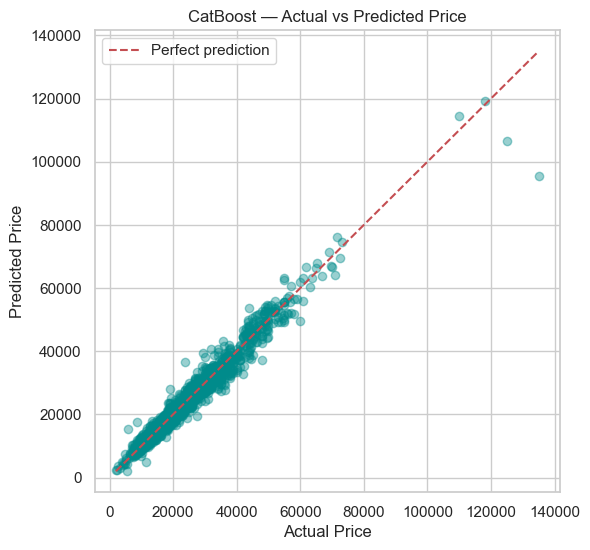

In [27]:
plt.figure(figsize=(6, 6))
plt.scatter(Y_test, y_pred_cat, alpha=0.4, color='darkcyan')
lims = [min(Y_test.min(), y_pred_cat.min()), max(Y_test.max(), y_pred_cat.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('CatBoost — Actual vs Predicted Price')
plt.legend()
plt.show()

## 8. Hyperparameter Tuning — RandomizedSearchCV (Random Forest)

Search over a randomized grid of Random Forest hyperparameters to see if tuning improves on the
default Random Forest above.

In [30]:
n_estimators = [int(x) for x in np.linspace(start=80, stop=1500, num=10)]
max_features = ['sqrt', 'log2']          # 'auto' was removed in newer scikit-learn versions
max_depth = [int(x) for x in np.linspace(6, 45, num=5)]
min_samples_split = [2, 5, 10, 15, 100]
min_samples_leaf = [1, 2, 5, 10]

rand_grid = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf
}

rf = RandomForestRegressor(random_state=0)
rcv = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rand_grid,
    scoring='neg_mean_squared_error',
    n_iter=10,
    cv=5,
    random_state=42,
    n_jobs=-1
)

rcv.fit(X_train, Y_train.ravel())
print("Best parameters found:")
rcv.best_params_

Best parameters found:


{'n_estimators': 1500,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_features': 'log2',
 'max_depth': 35}

In [31]:
rf_tuned_pred = rcv.predict(X_test)
evaluate('Random Forest (Tuned)', Y_test, rf_tuned_pred)

print("MSE:", mean_squared_error(Y_test, rf_tuned_pred))

Random Forest (Tuned)
  R2 Score : 0.9589
  MAE      : 1504.97
MSE: 5646106.942874504


## 9. Model Comparison

In [32]:
results_df = pd.DataFrame(results).T.sort_values('R2 Score', ascending=False)
results_df

,R2 Score,MAE
CatBoost,0.964161,1453.523070
Random Forest (Tuned),0.958912,1504.967469
Extra Trees,0.957066,1539.108145
Random Forest,0.953613,1538.730981
Linear Regression,0.791621,3381.673340


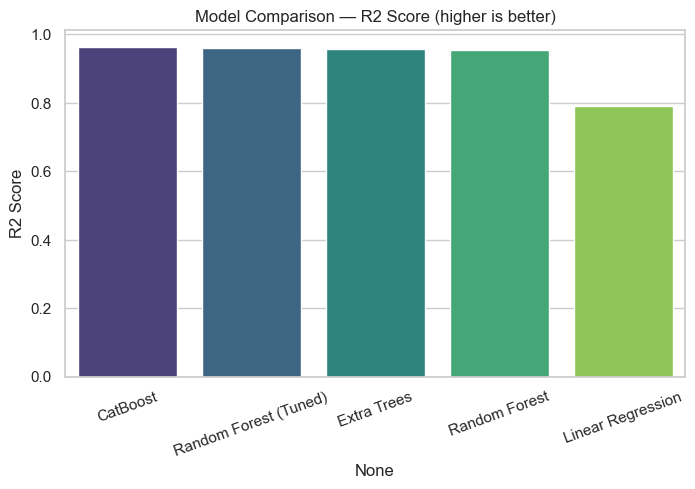

Best performing model on test data: CatBoost


In [33]:
plt.figure(figsize=(8, 4.5))
sns.barplot(x=results_df.index, y=results_df['R2 Score'], palette='viridis')
plt.title('Model Comparison — R2 Score (higher is better)')
plt.ylabel('R2 Score')
plt.xticks(rotation=20)
plt.show()

best_model_name = results_df['R2 Score'].idxmax()
print(f"Best performing model on test data: {best_model_name}")

## 10. Persist the Best Model

We save the CatBoost model (typically the strongest performer on tabular data with mixed
categorical/numeric features) so it can be reloaded later without retraining.

In [34]:
with open('model.pkl', 'wb') as f:
    pickle.dump(cat_reg, f)

print("Model saved to model.pkl")

Model saved to model.pkl


## 11. Reload the Model & Predict on the Full Dataset

Simulates using the saved model in a fresh session: load the pickle, run it on the full
(preprocessed) feature matrix `X`, and attach predictions back to the original data.

In [35]:
with open('model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

full_pred = loaded_model.predict(X)

result = df.copy()
result['Price Prediction'] = full_pred
result.head(10)

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Price Prediction
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4,13989.826721
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0,16578.038468
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4,12489.548001
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0,18793.884463
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0,18493.205301
5,A1,2016,13900,Automatic,32260,Petrol,30,58.9,1.4,13902.822210
6,A6,2016,13250,Automatic,76788,Diesel,30,61.4,2.0,15331.816498
7,A4,2016,11750,Manual,75185,Diesel,20,70.6,2.0,11950.406999
8,A3,2015,10200,Manual,46112,Petrol,20,60.1,1.4,12392.930688
9,A1,2016,12000,Manual,22451,Petrol,30,55.4,1.4,12902.995199


In [36]:
print('R2 Score  :', r2_score(Y, full_pred))
print('Mean Absolute Error:', mean_absolute_error(Y, full_pred))

R2 Score  : 0.9745608180217411
Mean Absolute Error: 1300.9813014378083


## 12. Conclusion

- The dataset contains 10,668 used-Audi listings with no missing values.
- After label-encoding `model`/`fuelType`, one-hot-encoding `transmission`, and standard-scaling
  all features, several regressors were trained and compared.
- Tree-based/boosting models (Random Forest, Extra Trees, CatBoost) substantially outperform plain
  Linear Regression, since price depends non-linearly on mileage, age and engine size.
- The best model (see the comparison table in Section 9) is saved to `model.pkl` and can be
  reloaded for inference on new listings without retraining, as shown in Section 11.
